# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.
- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.
- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

To perform exploratory and descriptive analyses, we will first gather information about the data's structure with .describe and .info. We will then check for missing values using df.isna().sum() and examine the eight input features. Next, we will plot the distribution of every variable using histograms or KDE plots to get a sense of the shape, skew, and any outliers. We can also create a correlation matrix to look at relationships between the input variables, which will help us determine if there is any multicollinearity.  

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

For preprocessing, we would first check for any missing values or duplicates in the dataset. We would then standardize the input features using StandardScaler (mean = 0, standard deviation = 1) in order to account for differences in feature scales. Then, by fitting this scaler on the training data within each cross-validation fold, we can use this to transform the validation data. Lastly, we would convert the data to PyTorch tensors. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

The outcome variable (`Concrete compressive strength(MPa, megapascals)`) is a continuous quantitative variable with a minimum of ~2.331 and a maximum of ~82.599. So, to predict this variable, we will be doing regression (as opposed to classification) because we are not predicting distinct classes and are instead predicting a value along a numeric scale. Since we are going linear regression, our cost function will be MSE and our output layer activation function will be linear/default (as in, leaving our prediction as a linear combination) -- with hidden layers using RELU.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

We will use k-fold cross-validation  with k=5. The dataset is shuffled once and split into 5 non-overlapping folds of roughly equal size (KFold(n_splits=5, shuffle=True, random_state=42)). Each fold is used as the held-out reporting set exactly once, while the other 4 folds form the training set. Every model has the same split. The fixed random_state gives all models (neural network, sklearn replication, SVM, linear regression) identical train/report splits, so the comparison is fair. For each fold, a StandardScaler is fit on the training portion only, then used to transform both the training and held-out portions. This prevents information from the held-out data leaking into training. Additionally, for each fold, a new model is created and trained from scratch on the training portion, with no hyperparameter tuning and no weights carried over between folds. After training, we will predict on the held-out fold and compute three metrics MSE, RMSE, and R^2. We will average each metric across the 5 folds and report those means as the model’s performance. Each fold’s results are also printed so the variability between folds is visible.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [3]:
import pandas as pd
df = pd.read_excel('Concrete_Data.xls')
df.head()

/tmp/ipykernel_8476/1869611279.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel('Concrete_Data.xls')


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [6]:
df.isna().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

In [16]:
print(df.duplicated().sum())

25


In [17]:
print(df.columns)

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')


<Axes: >

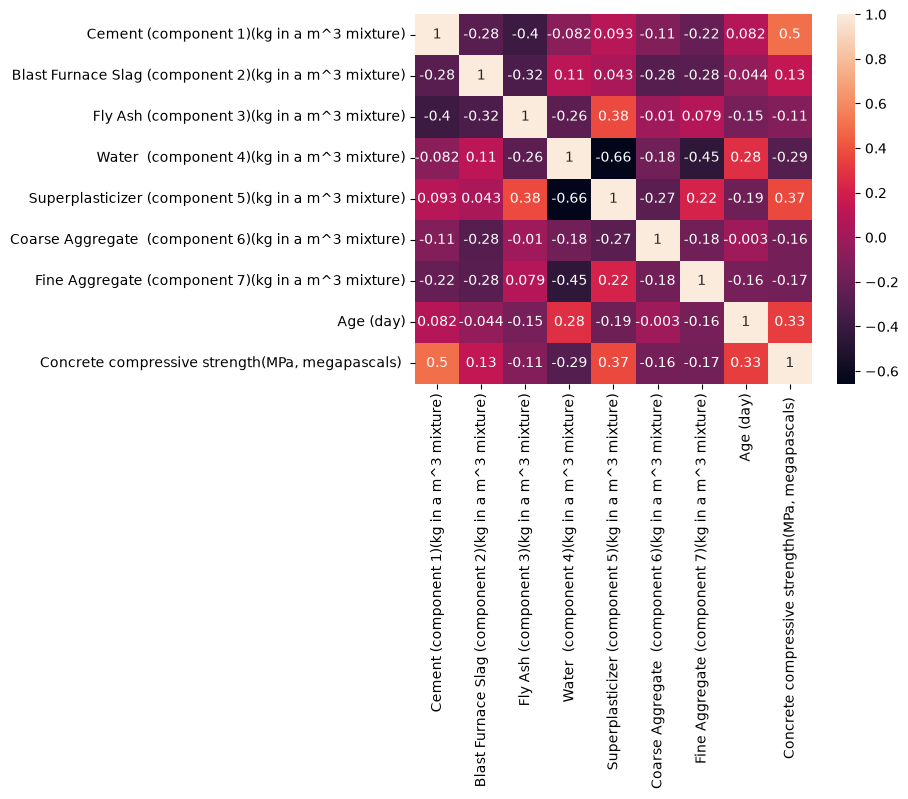

In [19]:
# print a correlation matrix only using the numeric data types in df
import seaborn as sns
numeric_features = df.select_dtypes(include=["int64", "float64"])
corr_matrix = numeric_features.corr()
sns.heatmap(corr_matrix, annot=True)

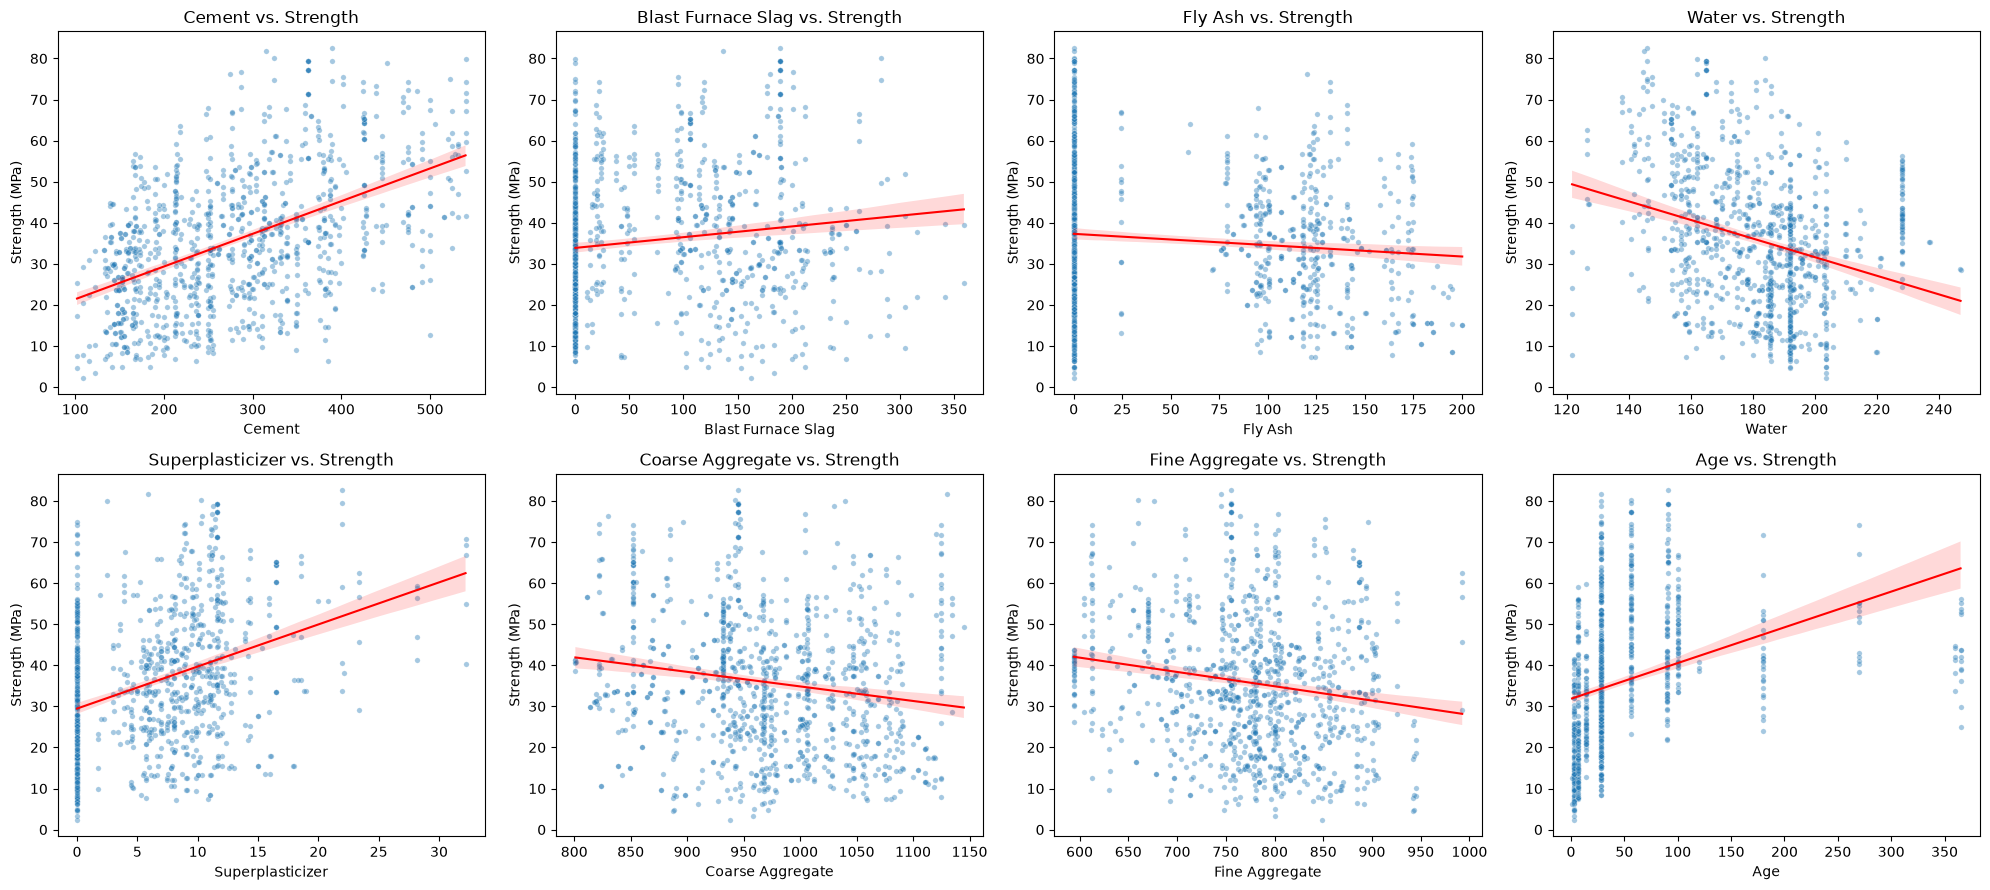

In [21]:
# scatterplots of each feature vs target variable
import matplotlib.pyplot as plt

target = 'Concrete compressive strength(MPa, megapascals) '
features = [c for c in df.columns if c != target]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sns.scatterplot(x=df[col], y=df[target], ax=ax, alpha=0.4, s=15)
    sns.regplot(x=df[col], y=df[target], ax=ax, scatter=False, color="red", line_kws={"linewidth": 1.5})
    short_name = col.split("(")[0].strip()
    ax.set_title(f"{short_name} vs. Strength")
    ax.set_xlabel(short_name)
    ax.set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()

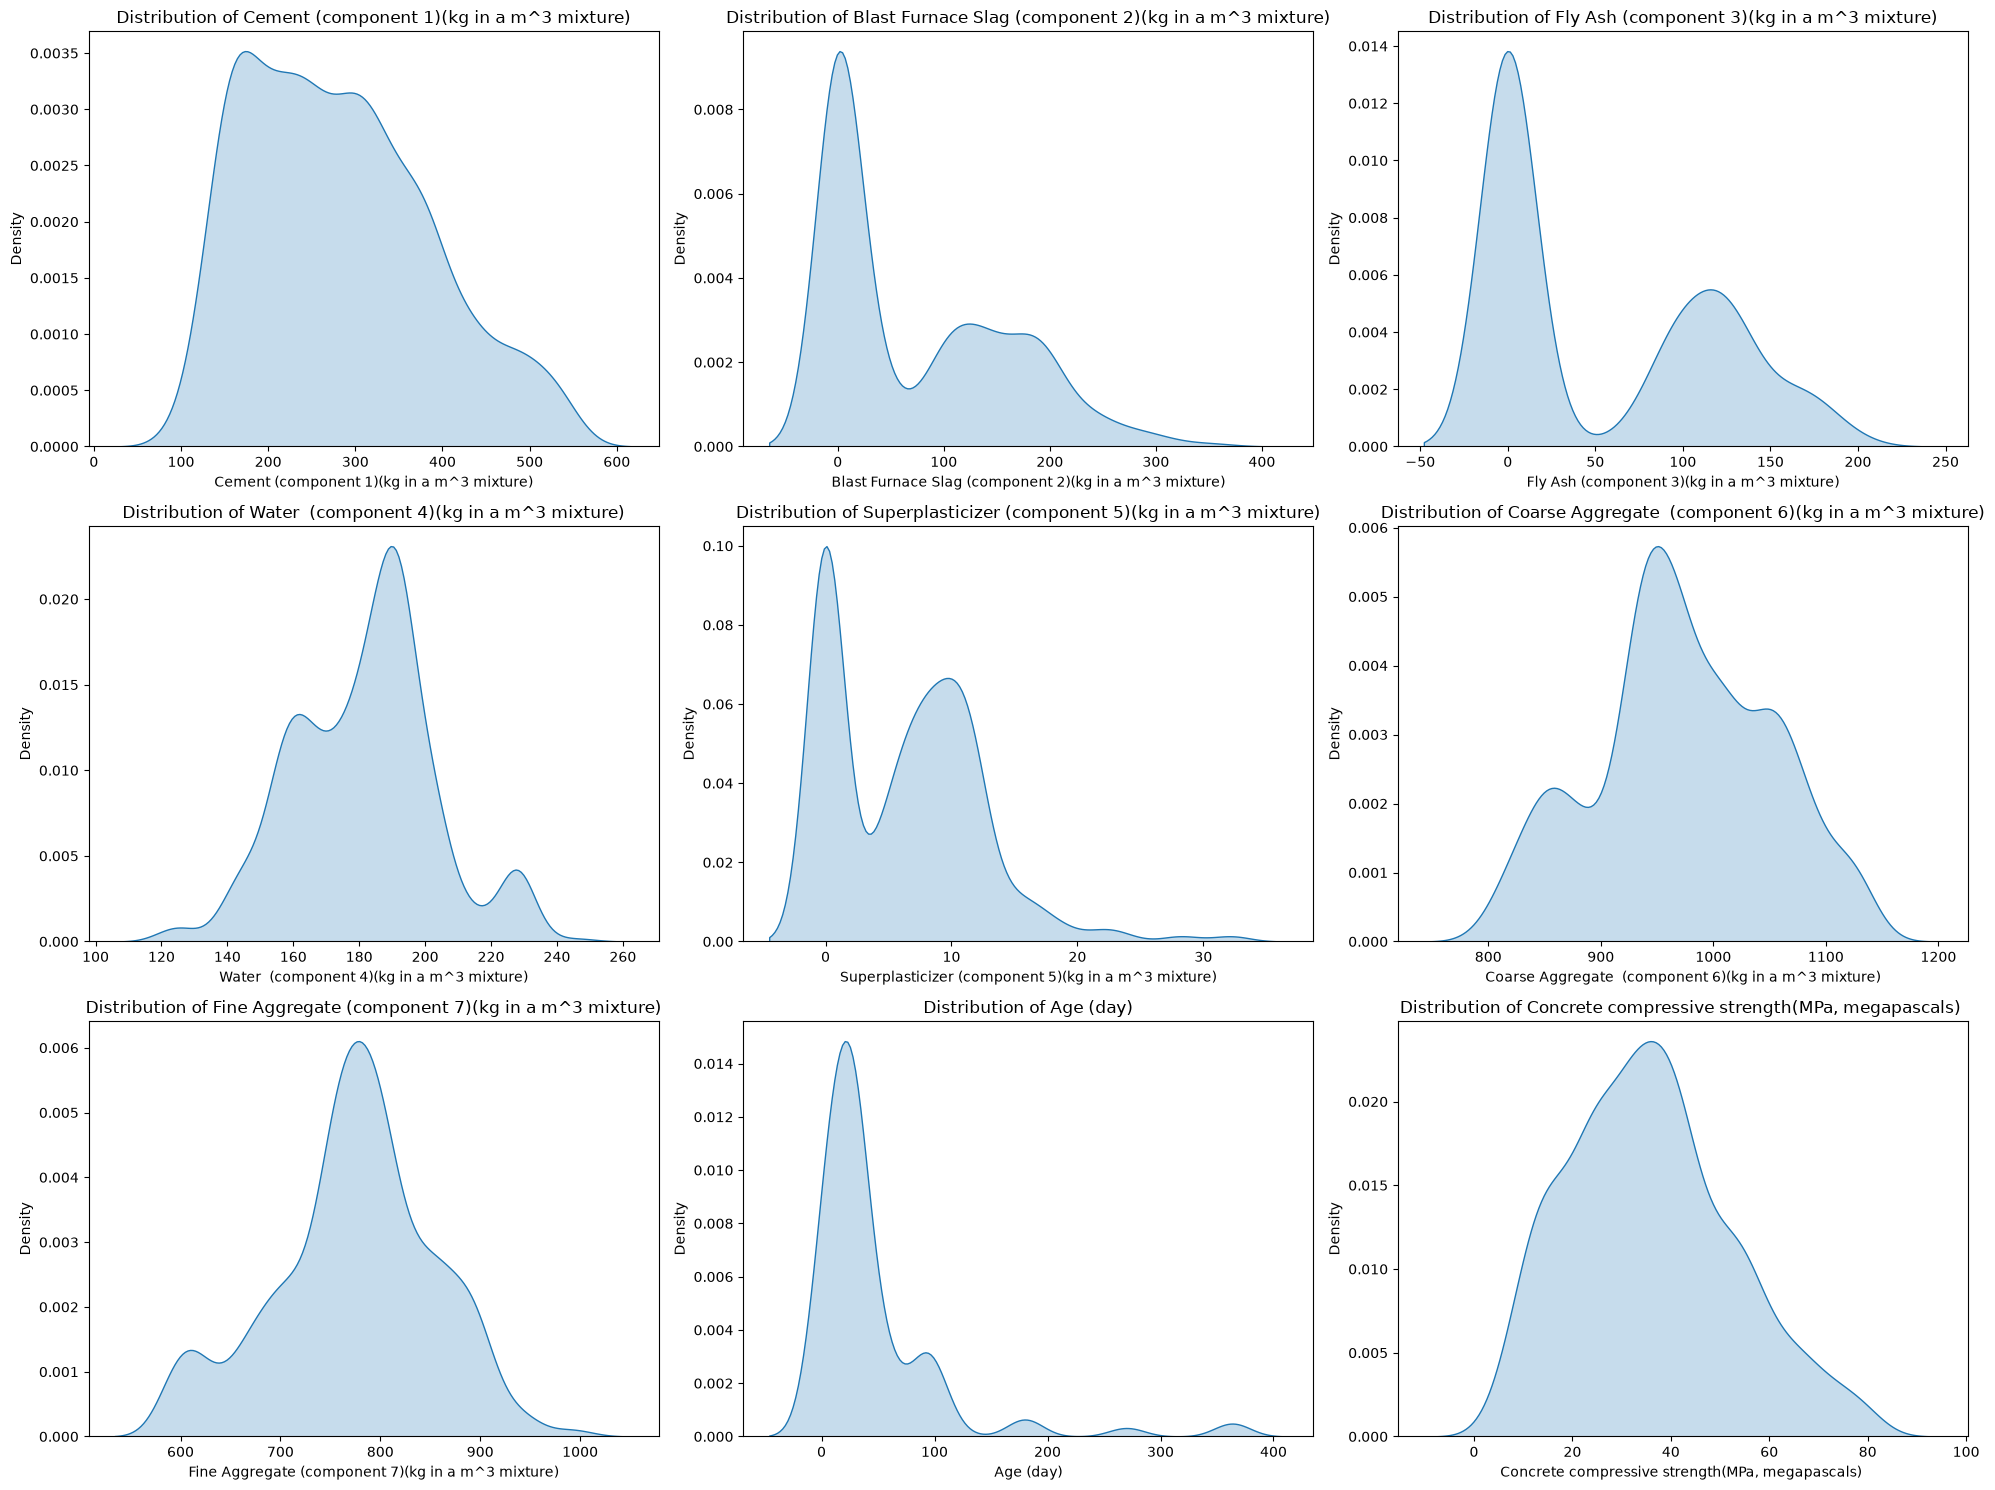

In [23]:
import matplotlib.pyplot as plt
num_cols = numeric_features.shape[1]

plt.figure(figsize=(20, 15))

for i in range(num_cols):
    col = numeric_features.columns[i]
    plt.subplot(3, 3, i + 1)
    sns.kdeplot(numeric_features[col], fill=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [24]:
# defining model
import torch
import torch.nn as nn
import torch.optim as optim

class NeuralNetwork(nn.Module): #inherit from nn.Module
    def __init__(self):
        super().__init__()  

        n_features = 8    
        hidden_size = 16

        l1 = nn.Linear(n_features, hidden_size)
        a1 = nn.ReLU()
        l2 = nn.Linear(hidden_size, 1)
        a2 = nn.Identity() # we can also leave a2 out b/c we will leave it as linear combination for regression - but wanted to code it as identity for clarity on structure of neural network :)
        l = [l1, a1, l2, a2]
        self.module_list = nn.ModuleList(l)

    def forward(self, X):
        for layer in self.module_list:
            X = layer(X)
        return X


# cost
cost_function = nn.MSELoss() # b/c we are doing regression

In [25]:
# data preprocessing
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Concrete compressive strength(MPa, megapascals) '])
y = df['Concrete compressive strength(MPa, megapascals) ']

In [26]:
# instantiation + evaluation w/ KFold

from sklearn.model_selection import KFold
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import r2_score #

k = 5
batch_size = 16
n_epochs = 100
kf = KFold(n_splits=k, shuffle=True, random_state=42)

## set up lists for evaluation
fold_mse = []
fold_rmse = []
fold_r2 = []

for fold, (ii, jj) in enumerate(kf.split(X), start=1):
    # split
    X_train, X_report = X.iloc[ii], X.iloc[jj]
    y_train, y_report = y.iloc[ii], y.iloc[jj]

    # scale
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_report = scaler.transform(X_report)

    # make into tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
    X_report = torch.tensor(X_report, dtype=torch.float32)
    y_report = torch.tensor(y_report.values, dtype=torch.float32).reshape(-1, 1)

    #use DataLoader for batch processing
    train_dataset = TensorDataset(X_train, y_train) 
    train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle=True)

    report_dataset = TensorDataset(X_report, y_report)
    report_loader = DataLoader(report_dataset, batch_size=batch_size, shuffle=False)

    # instantiate model + optimizer for each fold
    model = NeuralNetwork()
    cost_function = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # train
    train_costs=[] # reset at start of each fold

    for epoch in range(n_epochs):
        model.train() 

        running_cost = 0
        
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_probs = model(x_batch)
            cost = cost_function(y_probs, y_batch)
            cost.backward()
            optimizer.step()
            running_cost += cost.item()

        train_costs.append(running_cost / len(train_loader))

    # evaluation
    model.eval() 
    report_cost = 0.0
    total = 0
    preds=[]
    with torch.no_grad():  # No gradient tracking
        for x_batch, y_batch in report_loader:
            out = model(x_batch)
            cost = cost_function(out, y_batch)
            report_cost += cost.item() * x_batch.size(0)  
            total += y_batch.size(0)
            preds.append(out)

    mse = report_cost / len(jj) # we evalute using mse b/c that is te cost function for linear regression
    r2 = r2_score(y_report.numpy(), torch.cat(preds).numpy()) # we evaluate w/ r2 because it tells us how much variance in Y is explained by X
    fold_mse.append(mse)
    fold_rmse.append(np.sqrt(mse)) # root MSE to return to original units -- useful if we need to interpret later :)
    fold_r2.append(r2)
    print(f"Fold {fold}: MSE={mse:.2f}, RMSE={np.sqrt(mse):.2f}, R²={r2:.3f}")

    # per-fold sanity check :)
    avg_report_loss = report_cost / total
    print(f"Reporting Loss: {avg_report_loss:.4f}", "\n")



Fold 1: MSE=100.48, RMSE=10.02, R²=0.610
Reporting Loss: 100.4758 

Fold 2: MSE=92.32, RMSE=9.61, R²=0.724
Reporting Loss: 92.3180 

Fold 3: MSE=74.54, RMSE=8.63, R²=0.737
Reporting Loss: 74.5406 

Fold 4: MSE=84.14, RMSE=9.17, R²=0.702
Reporting Loss: 84.1397 

Fold 5: MSE=105.34, RMSE=10.26, R²=0.554
Reporting Loss: 105.3368 



In [27]:
print(f"\nAverage over {k} folds:")
print(f"MSE:  {np.mean(fold_mse):.2f}")
print(f"RMSE: {np.mean(fold_rmse):.2f}")
print(f"R²:   {np.mean(fold_r2):.3f}")


Average over 5 folds:
MSE:  91.36
RMSE: 9.54
R²:   0.665


## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [28]:
# imports
import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [29]:
# same as above, as NumPy arrays
target = 'Concrete compressive strength(MPa, megapascals) '
X_np = df.drop(columns=[target]).to_numpy()
y_np = df[target].to_numpy()

# same settings as the PyTorch experiment
k = 5
batch_size = 16
n_epochs = 100
kf = KFold(n_splits=k, shuffle=True, random_state=42)  # identical folds
sk_mse = []
sk_rmse = []
sk_r2 = []

In [30]:

for fold, (ii, jj) in enumerate(kf.split(X_np), start=1):
    # split
    X_tr, X_te = X_np[ii], X_np[jj]
    y_tr, y_te = y_np[ii], y_np[jj]

    # scale: fit on the training fold only to avoid leakage
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    # same architecture: 8 -> 16 (ReLU) -> 1 (identity output by default)
    mlp = MLPRegressor(
        hidden_layer_sizes=(16,),
        activation='relu',
        solver='adam',
        learning_rate_init=0.001,
        batch_size=batch_size,
        max_iter=n_epochs,
        alpha=0.0,                # no L2 penalty, matching the PyTorch model
        shuffle=True,
        tol=0,                    # don't stop early on small improvements
        n_iter_no_change=n_epochs,
        random_state=42
    )

    
    # evaluate on the held-out fold
    mlp.fit(X_tr, y_tr)
    preds = mlp.predict(X_te)
    mse = mean_squared_error(y_te, preds)
    r2 = r2_score(y_te, preds)

    sk_mse.append(mse)
    sk_rmse.append(np.sqrt(mse))
    sk_r2.append(r2)
    print(f"Fold {fold}: MSE={mse:.2f}, RMSE={np.sqrt(mse):.2f}, R²={r2:.3f}")

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 1: MSE=71.48, RMSE=8.45, R²=0.723


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 2: MSE=106.04, RMSE=10.30, R²=0.683


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 3: MSE=101.95, RMSE=10.10, R²=0.640


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 4: MSE=82.79, RMSE=9.10, R²=0.706
Fold 5: MSE=82.04, RMSE=9.06, R²=0.652


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [31]:
# averages
print(f"\nAverage over {k} folds (sklearn MLPRegressor):")
print(f"MSE:  {np.mean(sk_mse):.2f}")
print(f"RMSE: {np.mean(sk_rmse):.2f}")
print(f"R²:   {np.mean(sk_r2):.3f}")


Average over 5 folds (sklearn MLPRegressor):
MSE:  88.86
RMSE: 9.40
R²:   0.681


## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [ ]:
# imports
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# define cross-validation function
def fitted_model(make_model, X_np, y_np, kf, name):
    mses, rmses, r2s = [], [], []

    # 5-fold cross-validation, split into train and test for each fold
    for fold, (ii, jj) in enumerate(kf.split(X_np), start=1):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_np[ii])
        X_te = scaler.transform(X_np[jj])
        model = make_model()
        model.fit(X_tr, y_np[ii])
        preds = model.predict(X_te)

        # calculate MSE, RMSE, and r^2 for current fold
        mse = mean_squared_error(y_np[jj], preds)
        mses.append(mse); rmses.append(np.sqrt(mse)); r2s.append(r2_score(y_np[jj], preds))
        print(f"{name} Fold {fold}: MSE={mse:.2f}, RMSE={np.sqrt(mse):.2f}, R\u00b2={r2s[-1]:.3f}")
    print(f"\n{name} average over {len(mses)} folds: MSE={np.mean(mses):.2f}, RMSE={np.mean(rmses):.2f}, R\u00b2={np.mean(r2s):.3f}\n")
    return mses, rmses, r2s

In [33]:
# train both models
target = 'Concrete compressive strength(MPa, megapascals) '
X_np = df.drop(columns=[target]).to_numpy()
y_np = df[target].to_numpy()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [34]:
# train and evaluate SVM with RBF kernel
svm_mse, svm_rmse, svm_r2 = fitted_model(lambda: SVR(kernel='rbf'), X_np, y_np, kf, "SVM (RBF)")

# train and evaluate linear regression
lr_mse,  lr_rmse,  lr_r2  = fitted_model(lambda: LinearRegression(), X_np, y_np, kf, "Linear Regression")

SVM (RBF) Fold 1: MSE=88.98, RMSE=9.43, R²=0.655
SVM (RBF) Fold 2: MSE=135.75, RMSE=11.65, R²=0.594
SVM (RBF) Fold 3: MSE=95.50, RMSE=9.77, R²=0.663
SVM (RBF) Fold 4: MSE=88.17, RMSE=9.39, R²=0.687
SVM (RBF) Fold 5: MSE=85.06, RMSE=9.22, R²=0.639

SVM (RBF) average over 5 folds: MSE=98.69, RMSE=9.89, R²=0.648

Linear Regression Fold 1: MSE=95.98, RMSE=9.80, R²=0.628
Linear Regression Fold 2: MSE=135.91, RMSE=11.66, R²=0.594
Linear Regression Fold 3: MSE=125.35, RMSE=11.20, R²=0.557
Linear Regression Fold 4: MSE=90.94, RMSE=9.54, R²=0.677
Linear Regression Fold 5: MSE=106.88, RMSE=10.34, R²=0.547

Linear Regression average over 5 folds: MSE=111.01, RMSE=10.51, R²=0.601



In [35]:
# compare to neural network

# make dictionary that stores performance metrics for all four models
results = {
    "Neural Network (PyTorch)": (fold_mse, fold_rmse, fold_r2),
    "Neural Network (sklearn)": (sk_mse, sk_rmse, sk_r2),
    "SVM": (svm_mse, svm_rmse, svm_r2),
    "Linear Regression": (lr_mse, lr_rmse, lr_r2),
}

# make table that summarizes each model's performance
summary = pd.DataFrame({
    name: {"MSE (mean)": np.mean(m), "MSE (std)": np.std(m),
           "RMSE (mean)": np.mean(rm),
           "R\u00b2 (mean)": np.mean(r), "R\u00b2 (std)": np.std(r)}
    for name, (m, rm, r) in results.items()
}).T.round(3)
display(summary)

# make table with r^2 values for each fold
per_fold = pd.DataFrame({name: r for name, (_, _, r) in results.items()},
                        index=[f"Fold {i}" for i in range(1, 6)]).round(3)
display(per_fold)

,MSE (mean),MSE (std),RMSE (mean),R² (mean),R² (std)
Neural Network (PyTorch),91.362,11.085,9.540,0.665,0.071
Neural Network (sklearn),88.859,13.053,9.401,0.681,0.031
SVM,98.690,18.837,9.894,0.648,0.031
Linear Regression,111.011,17.154,10.505,0.601,0.048


,Neural Network (PyTorch),Neural Network (sklearn),SVM,Linear Regression
Fold 1,0.610,0.723,0.655,0.628
Fold 2,0.724,0.683,0.594,0.594
Fold 3,0.737,0.640,0.663,0.557
Fold 4,0.702,0.706,0.687,0.677
Fold 5,0.554,0.652,0.639,0.547


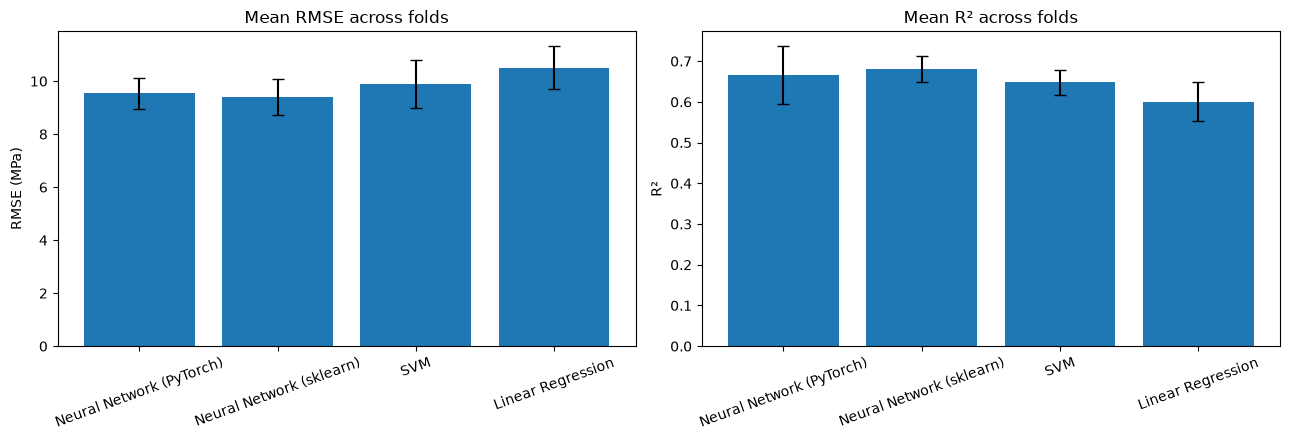

In [36]:
# plots to compare average RMSE and r^2 for each model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
names = list(results)

axes[0].bar(names, [np.mean(results[n][1]) for n in names],
            yerr=[np.std(results[n][1]) for n in names], capsize=4)
axes[0].set_ylabel("RMSE (MPa)"); axes[0].set_title("Mean RMSE across folds")
axes[1].bar(names, [np.mean(results[n][2]) for n in names],
            yerr=[np.std(results[n][2]) for n in names], capsize=4)
axes[1].set_ylabel("R\u00b2"); axes[1].set_title("Mean R\u00b2 across folds")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Similarities and Differences:**

The sklearn neural network performed best on average (R² = 0.681, RMSE = 9.401), followed by the PyTorch neural network (R² = 0.665, RMSE = 9.540), the SVM (R² = 0.648, RMSE = 9.894), and linear regression (R² = 0.601, RMSE = 10.505). The two neural networks used the same architecture, preprocessing, and folds, so their similar results make sense.

The SVM was slightly behind both neural networks (R² of 0.648 vs. 0.665 and 0.681), but the gap is small compared to the variation across folds, and the SVM beat the PyTorch network in Folds 1 and 5. Both can capture nonlinear relationships, which likely explains why their results are so close.

Linear regression was the weakest model (R² = 0.601, MSE = 111.011, compared to 91.362 and 88.859 for the neural networks). This suggests the relationship between ingredients and strength is partly nonlinear, which a straight-line model cannot capture. It still explained about 60% of the variance, so part of the relationship is roughly linear.

The best model changed from fold to fold because each fold holds out different rows of the data. No model was tuned, so these results show performance with default settings, not each model’s best possible performance. All models were evaluated with the same 5-fold cross-validation and preprocessing, so the comparison is fair.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our group kept the fold splits the same across all models, but we did not set a random seed for the PyTorch neural network. As a result, its results changed every time we reran the notebook, so the numbers in our written comparison sometimes didn’t match the final table and we had to go back and correct them before submitting. This cost us extra time and made it harder to be confident in our results. In the next lab, we will set a shared random seed in one cell at the top of the notebook and rerun the whole notebook once before writing any numbers into our reflection.